## Import Python libraries



In [2]:

# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully")


All libraries imported successfully


# Load the cleaned dataset  

In [4]:

# Loading the cleaned dataset

df = pd.read_csv('/content/SeoulBikeData_Cleaned.csv')

# Display first five rows

df.head()


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


# Check the number of rows and columns

In [5]:

# Checking dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])


Number of Rows: 8760
Number of Columns: 14


# Display all column names

In [6]:

# Displaying all column names

print(df.columns.tolist())


['date', 'rented_bike_count', 'hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point_temperature', 'solar_radiation', 'rainfall', 'snowfall', 'seasons', 'holiday', 'functioning_day']


# Check dataset information

In [7]:

# Checking dataset information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   object 
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed             8760 non-null   float64
 6   visibility             8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation        8760 non-null   float64
 9   rainfall               8760 non-null   float64
 10  snowfall               8760 non-null   float64
 11  seasons                8760 non-null   object 
 12  holiday                8760 non-null   object 
 13  functioning_day        8760 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 958.3+ 

# Display first and last five records

In [8]:

# First five records

display(df.head())

# Last five records

display(df.tail())


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
8755,2018-11-30,1003,19,4.2,34,2.6,1894,-10.3,0.0,0.0,0.0,Autumn,No Holiday,Yes
8756,2018-11-30,764,20,3.4,37,2.3,2000,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8757,2018-11-30,694,21,2.6,39,0.3,1968,-9.9,0.0,0.0,0.0,Autumn,No Holiday,Yes
8758,2018-11-30,712,22,2.1,41,1.0,1859,-9.8,0.0,0.0,0.0,Autumn,No Holiday,Yes
8759,2018-11-30,584,23,1.9,43,1.3,1909,-9.3,0.0,0.0,0.0,Autumn,No Holiday,Yes


# Descriptive Statistics

In [9]:

# Descriptive statistics of numerical columns

df.describe()


,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


# Calculate mean

In [10]:

# Calculating mean

df.mean(numeric_only=True)


,0
rented_bike_count,704.602055
hour,11.500000
temperature,12.882922
humidity,58.226256
wind_speed,1.724909
visibility,1436.825799
dew_point_temperature,4.073813
solar_radiation,0.569111
rainfall,0.148687
snowfall,0.075068


# Calculate median

In [11]:

# Calculating median

df.median(numeric_only=True)


,0
rented_bike_count,504.50
hour,11.50
temperature,13.70
humidity,57.00
wind_speed,1.50
visibility,1698.00
dew_point_temperature,5.10
solar_radiation,0.01
rainfall,0.00
snowfall,0.00


# Calculate standard deviation

In [12]:

# Calculating standard deviation

df.std(numeric_only=True)


,0
rented_bike_count,644.997468
hour,6.922582
temperature,11.944825
humidity,20.362413
wind_speed,1.036300
visibility,608.298712
dew_point_temperature,13.060369
solar_radiation,0.868746
rainfall,1.128193
snowfall,0.436746


# Calculate minimum and maximum

In [13]:

# Minimum values

print("Minimum Values:")
print(df.min(numeric_only=True))

# Maximum values

print("\nMaximum Values:")
print(df.max(numeric_only=True))


Minimum Values:
rented_bike_count         0.0
hour                      0.0
temperature             -17.8
humidity                  0.0
wind_speed                0.0
visibility               27.0
dew_point_temperature   -30.6
solar_radiation           0.0
rainfall                  0.0
snowfall                  0.0
dtype: float64

Maximum Values:
rented_bike_count        3556.00
hour                       23.00
temperature                39.40
humidity                   98.00
wind_speed                  7.40
visibility               2000.00
dew_point_temperature      27.20
solar_radiation             3.52
rainfall                   35.00
snowfall                    8.80
dtype: float64


# Exploratory Data Analysis (EDA)

In [14]:

# Checking dataset structure

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst Five Records:")
display(df.head())


Dataset Shape: (8760, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   8760 non-null   object 
 1   rented_bike_count      8760 non-null   int64  
 2   hour                   8760 non-null   int64  
 3   temperature            8760 non-null   float64
 4   humidity               8760 non-null   int64  
 5   wind_speed             8760 non-null   float64
 6   visibility             8760 non-null   int64  
 7   dew_point_temperature  8760 non-null   float64
 8   solar_radiation        8760 non-null   float64
 9   rainfall               8760 non-null   float64
 10  snowfall               8760 non-null   float64
 11  seasons                8760 non-null   object 
 12  holiday                8760 non-null   object 
 13  functioning_day        8760 non-null   object 
dtypes: float

,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


# Check missing values

In [15]:

# Checking missing values

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:",
      df.isnull().sum().sum())


Missing Values in Each Column:
date                     0
rented_bike_count        0
hour                     0
temperature              0
humidity                 0
wind_speed               0
visibility               0
dew_point_temperature    0
solar_radiation          0
rainfall                 0
snowfall                 0
seasons                  0
holiday                  0
functioning_day          0
dtype: int64

Total Missing Values: 0


# Check duplicate records

In [16]:

# Checking duplicate records

print("Total Duplicate Records:",
      df.duplicated().sum())


Total Duplicate Records: 0


# Analyse numerical variables

In [17]:

# Summary of numerical variables

numerical_data = df.select_dtypes(include=np.number)

display(numerical_data.describe())


,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


# Analyse categorical variables

In [18]:

# Checking categorical variables

categorical_columns = [
    'seasons',
    'holiday',
    'functioning_day'
]

for col in categorical_columns:

    print("\nFrequency Distribution of", col)

    print(df[col].value_counts())



Frequency Distribution of seasons
seasons
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64

Frequency Distribution of holiday
holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64

Frequency Distribution of functioning_day
functioning_day
Yes    8465
No      295
Name: count, dtype: int64


# Identify outliers using boxplots

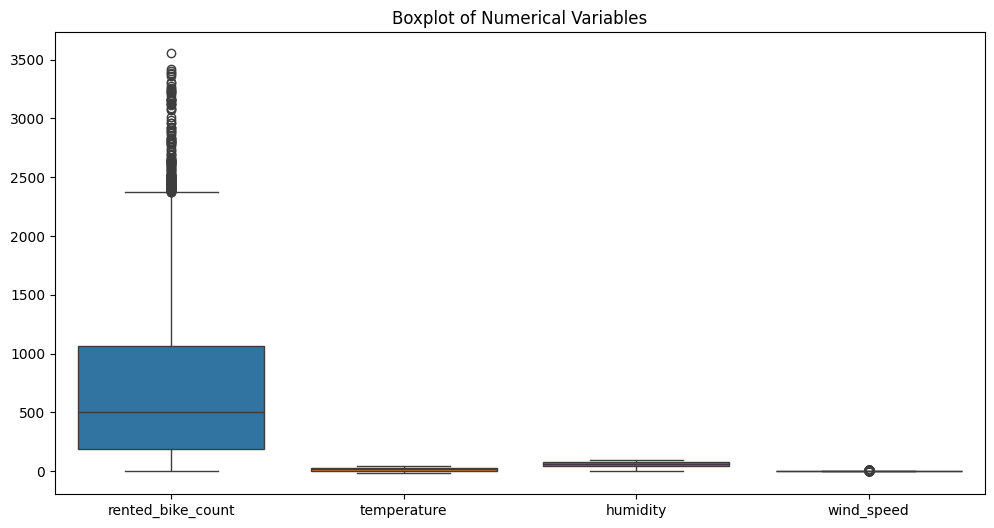

In [19]:

# Boxplot for detecting outliers

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[['rented_bike_count',
                     'temperature',
                     'humidity',
                     'wind_speed']])

plt.title("Boxplot of Numerical Variables")

plt.show()


# Analyse bike rental demand by hour

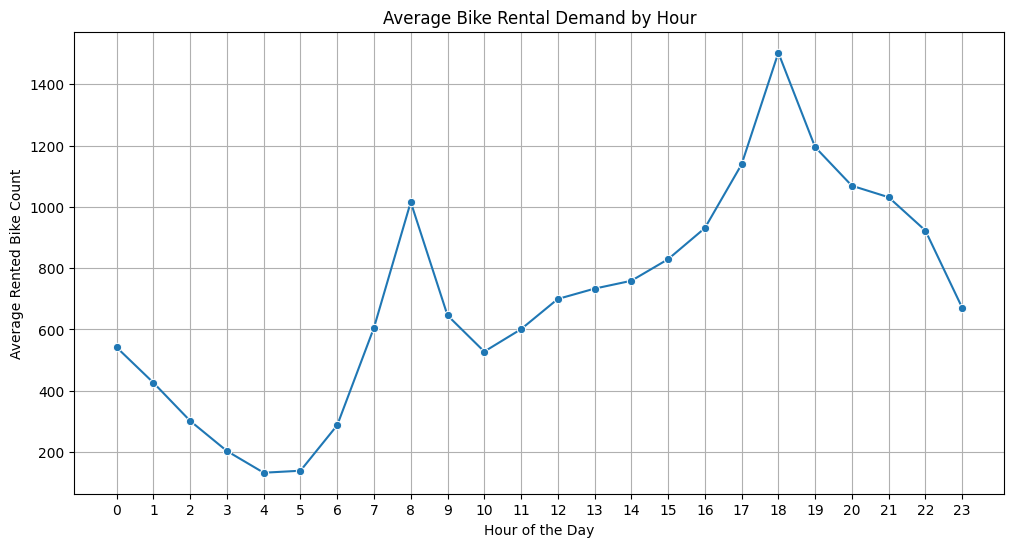

In [20]:

# Average bike rentals by hour

hourly_demand = df.groupby('hour', observed=True)[
    'rented_bike_count'
].mean()

plt.figure(figsize=(12, 6))

sns.lineplot(x=hourly_demand.index,
             y=hourly_demand.values,
             marker='o')

plt.title("Average Bike Rental Demand by Hour")

plt.xlabel("Hour of the Day")
plt.ylabel("Average Rented Bike Count")

plt.xticks(range(0, 24))

plt.grid(True)
plt.show()


# Analyse bike rental demand by season

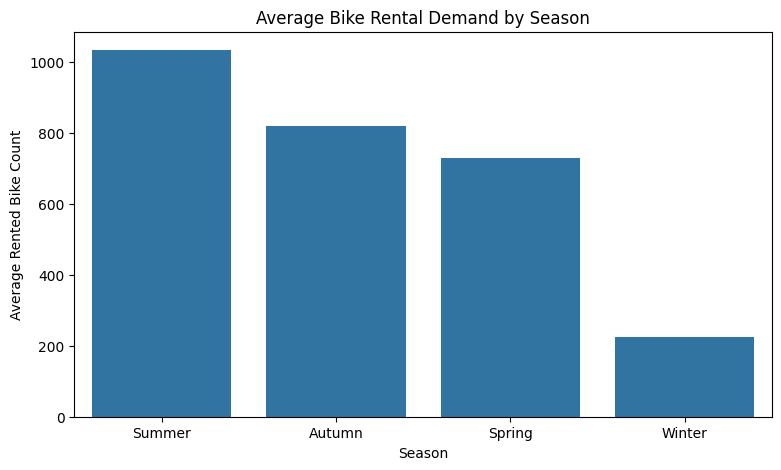

In [21]:

# Bike rental demand by season

season_demand = df.groupby(
    'seasons',
    observed=True
)['rented_bike_count'].mean().sort_values(
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(x=season_demand.index,
            y=season_demand.values)

plt.title("Average Bike Rental Demand by Season")

plt.xlabel("Season")
plt.ylabel("Average Rented Bike Count")

plt.show()



# Analyse relationship between temperature and bike rentals

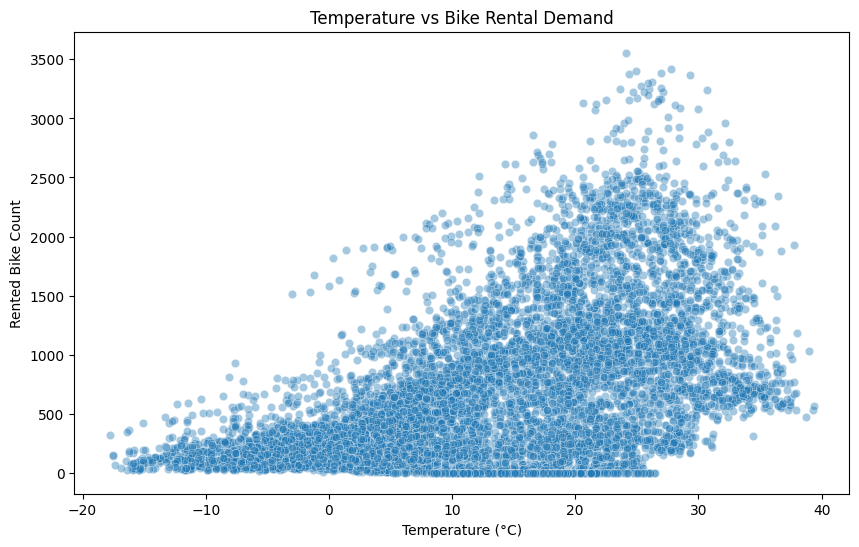

In [22]:

# Temperature vs Bike Rental Demand

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='temperature',
    y='rented_bike_count',
    alpha=0.4
)

plt.title("Temperature vs Bike Rental Demand")

plt.xlabel("Temperature (°C)")
plt.ylabel("Rented Bike Count")

plt.show()


# Analyse correlation between numerical variables

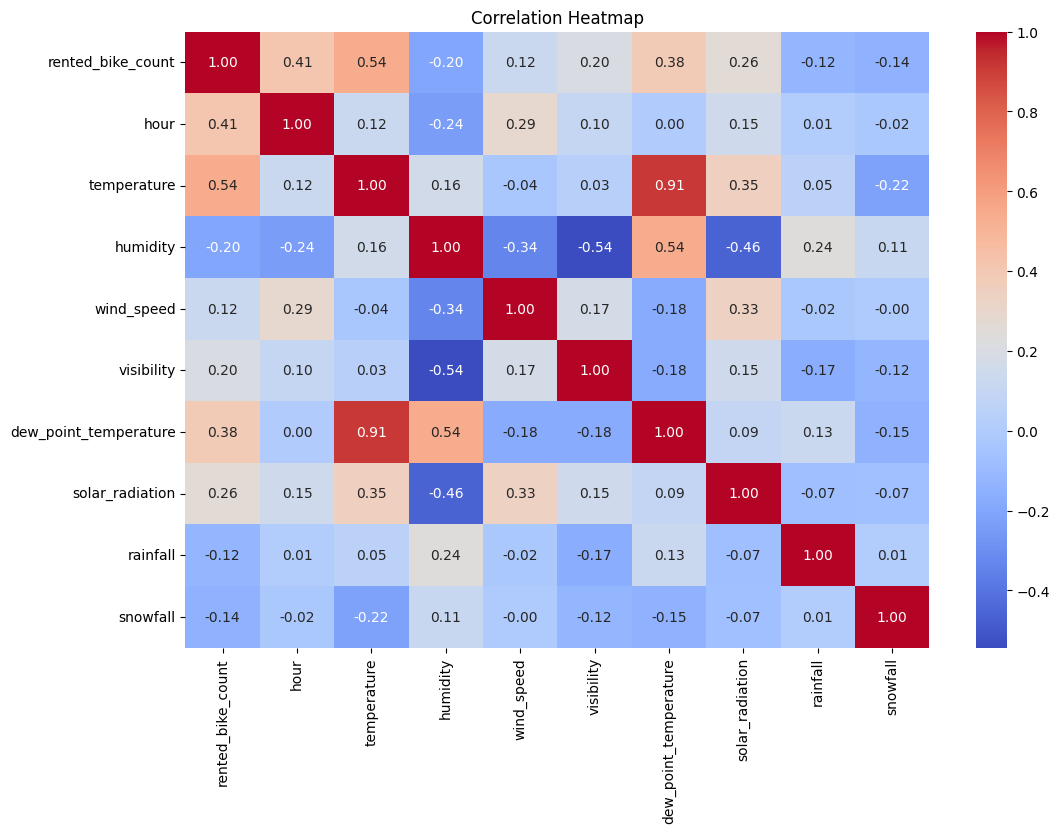

In [23]:

# Correlation analysis

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()


# Analyse bike rentals on holidays

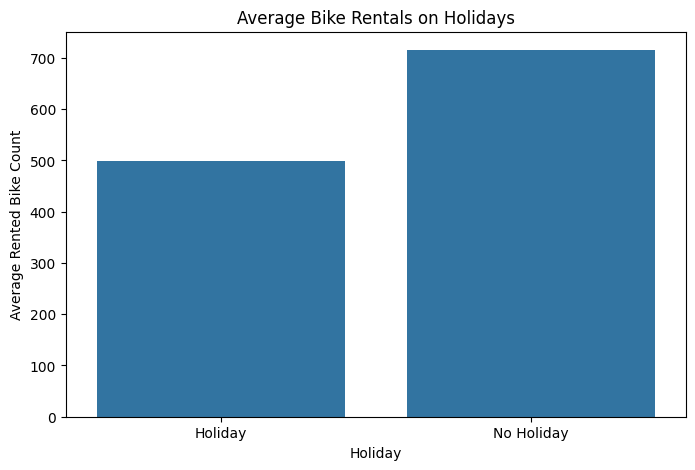

In [24]:

# Bike rental demand by holiday status

holiday_demand = df.groupby(
    'holiday',
    observed=True
)['rented_bike_count'].mean()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=holiday_demand.index,
    y=holiday_demand.values
)

plt.title("Average Bike Rentals on Holidays")

plt.xlabel("Holiday")
plt.ylabel("Average Rented Bike Count")

plt.show()


# Graph 1: Hourly bike rental demand

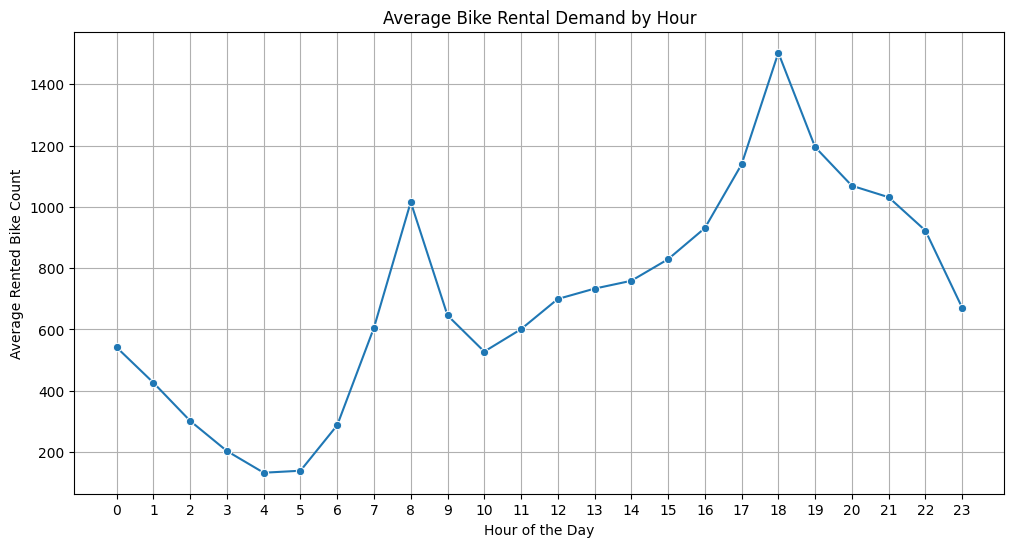

In [25]:

# Average bike rental demand by hour

hourly_demand = df.groupby('hour')['rented_bike_count'].mean()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker='o'
)

plt.title('Average Bike Rental Demand by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Rented Bike Count')
plt.xticks(range(0, 24))
plt.grid(True)

plt.savefig('Graph1_Hourly_Demand.png', dpi=300, bbox_inches='tight')
plt.show()


# Graph 2: Bike rental demand by season

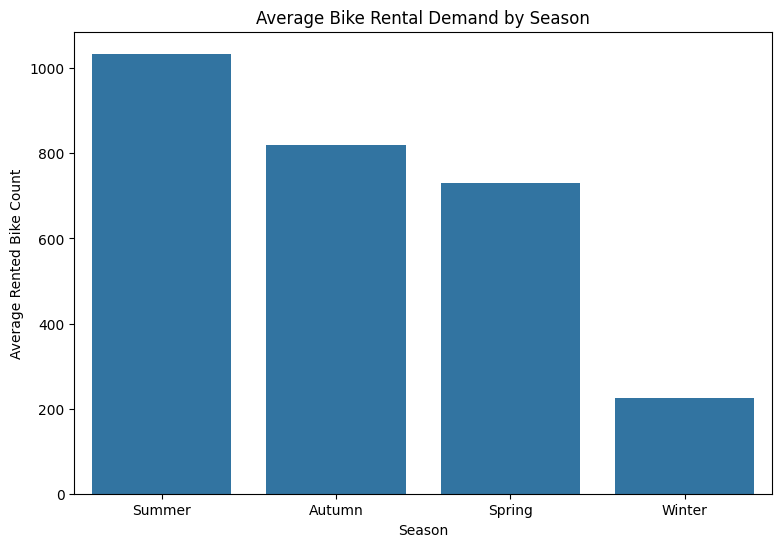

In [26]:

# Average bike rentals by season

season_demand = df.groupby(
    'seasons',
    observed=True
)['rented_bike_count'].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=season_demand.index,
    y=season_demand.values
)

plt.title('Average Bike Rental Demand by Season')
plt.xlabel('Season')
plt.ylabel('Average Rented Bike Count')

plt.savefig('Graph2_Seasonal_Demand.png', dpi=300, bbox_inches='tight')
plt.show()


# Graph 3: Temperature and bike rental demand

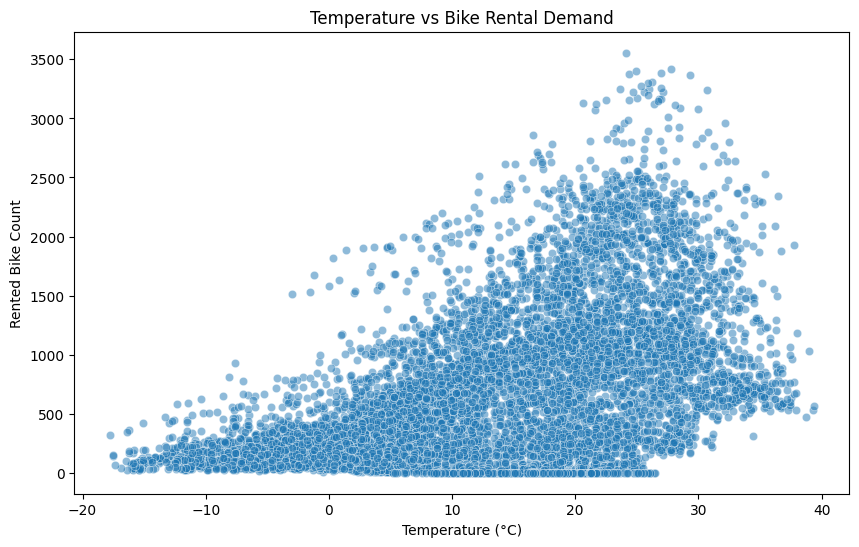

In [27]:

# Relationship between temperature and bike rentals

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='temperature',
    y='rented_bike_count',
    alpha=0.5
)

plt.title('Temperature vs Bike Rental Demand')
plt.xlabel('Temperature (°C)')
plt.ylabel('Rented Bike Count')

plt.savefig('Graph3_Temperature_Demand.png', dpi=300, bbox_inches='tight')
plt.show()


# Graph 4: Bike rental demand on holidays

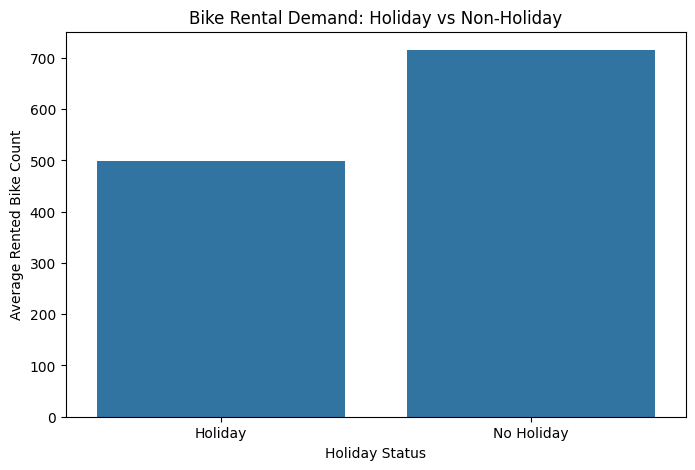

In [28]:

# Average rentals by holiday status

holiday_demand = df.groupby(
    'holiday',
    observed=True
)['rented_bike_count'].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=holiday_demand,
    x='holiday',
    y='rented_bike_count'
)

plt.title('Bike Rental Demand: Holiday vs Non-Holiday')
plt.xlabel('Holiday Status')
plt.ylabel('Average Rented Bike Count')

plt.savefig('Graph4_Holiday_Demand.png', dpi=300, bbox_inches='tight')
plt.show()


# Graph 5: Functioning day vs non-functioning day

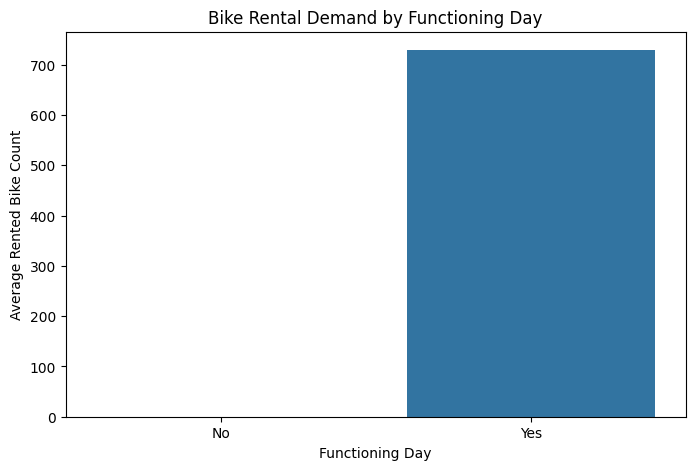

In [29]:

# Average bike rentals by functioning day

functioning_demand = df.groupby(
    'functioning_day',
    observed=True
)['rented_bike_count'].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=functioning_demand,
    x='functioning_day',
    y='rented_bike_count'
)

plt.title('Bike Rental Demand by Functioning Day')
plt.xlabel('Functioning Day')
plt.ylabel('Average Rented Bike Count')

plt.savefig('Graph5_Functioning_Day.png', dpi=300, bbox_inches='tight')
plt.show()


# Graph 6: Correlation heatmap

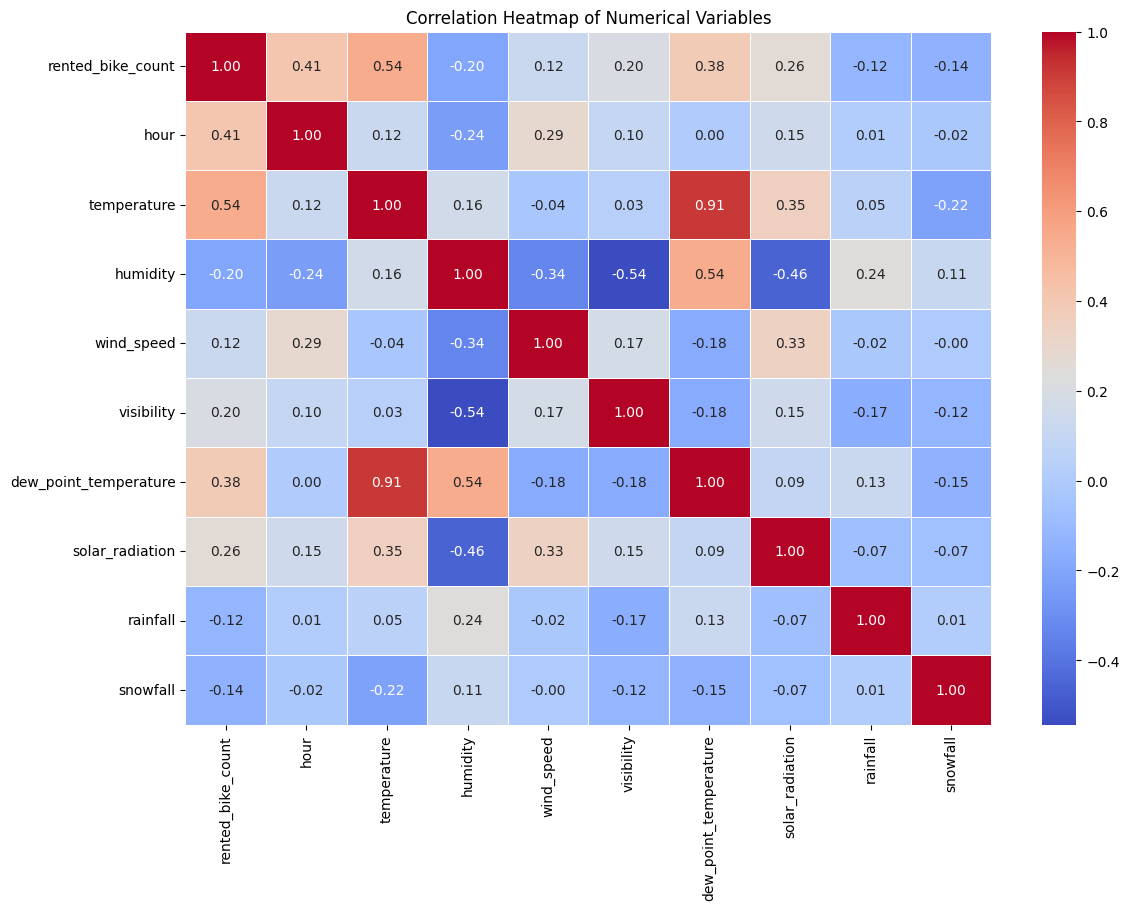

In [30]:

# Correlation heatmap

numerical_data = df.select_dtypes(include=np.number)

plt.figure(figsize=(13, 9))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')

plt.savefig('Graph6_Correlation_Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


# Create a visualisation summary table

In [31]:

# Visualisation summary

print("AVERAGE BIKE RENTAL DEMAND BY HOUR")
display(df.groupby('hour')['rented_bike_count'].mean().reset_index())

print("AVERAGE BIKE RENTAL DEMAND BY SEASON")
display(df.groupby('seasons', observed=True)['rented_bike_count'].mean().reset_index())

print("AVERAGE BIKE RENTAL DEMAND BY HOLIDAY")
display(df.groupby('holiday', observed=True)['rented_bike_count'].mean().reset_index())

print("AVERAGE BIKE RENTAL DEMAND BY FUNCTIONING DAY")
display(df.groupby('functioning_day', observed=True)['rented_bike_count'].mean().reset_index())


AVERAGE BIKE RENTAL DEMAND BY HOUR


,hour,rented_bike_count
0,0,541.460274
1,1,426.183562
2,2,301.630137
3,3,203.331507
4,4,132.591781
5,5,139.082192
6,6,287.564384
7,7,606.005479
8,8,1015.701370
9,9,645.983562


AVERAGE BIKE RENTAL DEMAND BY SEASON


,seasons,rented_bike_count
0,Autumn,819.597985
1,Spring,730.031250
2,Summer,1034.073370
3,Winter,225.541204


AVERAGE BIKE RENTAL DEMAND BY HOLIDAY


,holiday,rented_bike_count
0,Holiday,499.756944
1,No Holiday,715.228026


AVERAGE BIKE RENTAL DEMAND BY FUNCTIONING DAY


,functioning_day,rented_bike_count
0,No,0.000000
1,Yes,729.156999


# Save all six graphs

In [32]:

# Downloading all visualisation graphs

import os
import zipfile
from google.colab import files

graph_files = [
    'Graph1_Hourly_Demand.png',
    'Graph2_Seasonal_Demand.png',
    'Graph3_Temperature_Demand.png',
    'Graph4_Holiday_Demand.png',
    'Graph5_Functioning_Day.png',
    'Graph6_Correlation_Heatmap.png'
]

with zipfile.ZipFile('Seoul_Bike_Visualisations.zip', 'w') as zipf:
    for file in graph_files:
        if os.path.exists(file):
            zipf.write(file)

files.download('Seoul_Bike_Visualisations.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Import regression libraries

In [33]:

# Importing regression libraries

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Regression libraries imported successfully")


Regression libraries imported successfully


# Select dependent and independent variables

In [34]:

# Selecting dependent variable

y = df['rented_bike_count']

# Selecting independent variables

X = df[[
    'hour',
    'temperature',
    'humidity',
    'wind_speed',
    'visibility',
    'solar_radiation',
    'rainfall',
    'snowfall',
    'seasons',
    'holiday',
    'functioning_day'
]]

print("Independent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(y.name)


Independent Variables:
['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'solar_radiation', 'rainfall', 'snowfall', 'seasons', 'holiday', 'functioning_day']

Dependent Variable:
rented_bike_count


# Convert categorical variables into numerical form

In [35]:

# Converting categorical variables into dummy variables

X = pd.get_dummies(
    X,
    columns=['seasons', 'holiday', 'functioning_day'],
    drop_first=True,
    dtype=int
)

# Display encoded dataset

display(X.head())

print("Total Independent Variables:", X.shape[1])


,hour,temperature,humidity,wind_speed,visibility,solar_radiation,rainfall,snowfall,seasons_Spring,seasons_Summer,seasons_Winter,holiday_No Holiday,functioning_day_Yes
0,0,-5.2,37,2.2,2000,0.0,0.0,0.0,0,0,1,1,1
1,1,-5.5,38,0.8,2000,0.0,0.0,0.0,0,0,1,1,1
2,2,-6.0,39,1.0,2000,0.0,0.0,0.0,0,0,1,1,1
3,3,-6.2,40,0.9,2000,0.0,0.0,0.0,0,0,1,1,1
4,4,-6.0,36,2.3,2000,0.0,0.0,0.0,0,0,1,1,1


Total Independent Variables: 13


# Divide data into training and testing datasets

In [36]:

# Splitting the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (7008, 13)
Testing Data: (1752, 13)


# Build the Multiple Linear Regression model

In [37]:

# Creating Multiple Linear Regression Model

model = LinearRegression()

# Training the model

model.fit(X_train, y_train)

print("Multiple Linear Regression Model Trained Successfully")


Multiple Linear Regression Model Trained Successfully


# Make predictions

In [38]:

# Predicting bike rental demand

y_pred = model.predict(X_test)

# Display actual and predicted values

comparison = pd.DataFrame({
    'Actual Bike Rentals': y_test.values,
    'Predicted Bike Rentals': y_pred
})

display(comparison.head(10))


,Actual Bike Rentals,Predicted Bike Rentals
0,1728,949.516050
1,822,1131.582176
2,658,1353.273329
3,2716,1326.746489
4,1083,544.468530
5,636,790.159632
6,1537,1481.626795
7,712,1098.348100
8,425,951.855636
9,594,811.098126


# Evaluate model performance

In [39]:

# Evaluating regression model

r2 = r2_score(y_test, y_pred)

n = len(y_test)
p = X_test.shape[1]

adjusted_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

print("MODEL PERFORMANCE")
print("-------------------------")

print("R-squared:", round(r2, 4))
print("Adjusted R-squared:", round(adjusted_r2, 4))
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))


MODEL PERFORMANCE
-------------------------
R-squared: 0.5329
Adjusted R-squared: 0.5294
Mean Absolute Error: 330.95
Mean Squared Error: 194612.14
Root Mean Squared Error: 441.15


# Display regression coefficients

In [40]:

# Displaying regression coefficients

coefficients = pd.DataFrame({
    'Independent Variable': X.columns,
    'Coefficient': model.coef_
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

display(coefficients)

print("Intercept:", model.intercept_)


,Independent Variable,Coefficient
12,functioning_day_Yes,946.155777
11,holiday_No Holiday,125.161814
0,hour,28.244215
7,snowfall,27.241839
1,temperature,26.527114
3,wind_speed,17.935499
4,visibility,0.013047
2,humidity,-7.763263
6,rainfall,-62.923606
5,solar_radiation,-81.128567


Intercept: -373.94598217554267


# Actual vs predicted visualisation

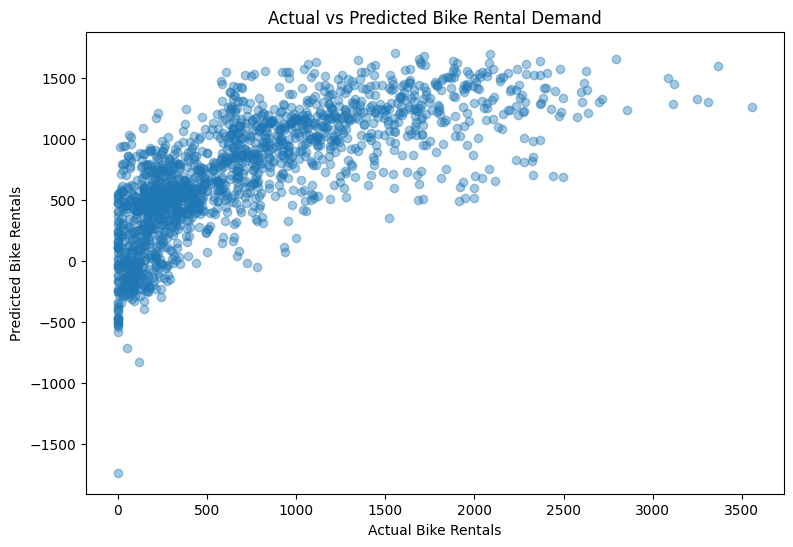

In [41]:

# Actual vs Predicted Bike Rentals

plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")

plt.title("Actual vs Predicted Bike Rental Demand")

plt.show()


# Save the regression results

In [42]:

# Saving regression coefficients

coefficients.to_csv(
    'Regression_Without_Interaction_Coefficients.csv',
    index=False
)

# Saving actual and predicted values

comparison.to_csv(
    'Regression_Predictions.csv',
    index=False
)

print("Regression results saved successfully!")


Regression results saved successfully!


# Multiple Linear Regression With Interaction Terms

# Cell 1: Create the independent variables again

In [45]:
X_interaction = df[['hour', 'temperature', 'humidity',
                    'wind_speed', 'visibility',
                    'solar_radiation', 'rainfall', 'snowfall',
                    'seasons', 'holiday', 'functioning_day']].copy()

y = df['rented_bike_count']

# Create interaction terms

In [46]:
X_interaction['temperature_humidity'] = (
    X_interaction['temperature'] * X_interaction['humidity']
)

X_interaction = pd.get_dummies(
    X_interaction,
    columns=['seasons', 'holiday', 'functioning_day'],
    drop_first=True,
    dtype=int
)

season_columns = [
    col for col in X_interaction.columns if col.startswith('seasons_')
]

holiday_columns = [
    col for col in X_interaction.columns if col.startswith('holiday_')
]

for col in season_columns:
    X_interaction['temperature_x_' + col] = (
        X_interaction['temperature'] * X_interaction[col]
    )

for col in holiday_columns:
    X_interaction['hour_x_' + col] = (
        X_interaction['hour'] * X_interaction[col]
    )

display(X_interaction.head())

,hour,temperature,humidity,wind_speed,visibility,solar_radiation,rainfall,snowfall,temperature_humidity,seasons_Spring,seasons_Summer,seasons_Winter,holiday_No Holiday,functioning_day_Yes,temperature_x_seasons_Spring,temperature_x_seasons_Summer,temperature_x_seasons_Winter,hour_x_holiday_No Holiday
0,0,-5.2,37,2.2,2000,0.0,0.0,0.0,-192.4,0,0,1,1,1,-0.0,-0.0,-5.2,0
1,1,-5.5,38,0.8,2000,0.0,0.0,0.0,-209.0,0,0,1,1,1,-0.0,-0.0,-5.5,1
2,2,-6.0,39,1.0,2000,0.0,0.0,0.0,-234.0,0,0,1,1,1,-0.0,-0.0,-6.0,2
3,3,-6.2,40,0.9,2000,0.0,0.0,0.0,-248.0,0,0,1,1,1,-0.0,-0.0,-6.2,3
4,4,-6.0,36,2.3,2000,0.0,0.0,0.0,-216.0,0,0,1,1,1,-0.0,-0.0,-6.0,4


# Split the dataset

In [47]:
X_train_interaction, X_test_interaction, y_train, y_test = train_test_split(
    X_interaction, y, test_size=0.20, random_state=42
)

# Train the interaction model

In [48]:
model_interaction = LinearRegression()

model_interaction.fit(
    X_train_interaction,
    y_train
)

print("Interaction Model Training Completed")

Interaction Model Training Completed


# Make predictions

In [49]:
y_pred_interaction = model_interaction.predict(X_test_interaction)

interaction_comparison = pd.DataFrame({
    'Actual Bike Rentals': y_test.values,
    'Predicted Bike Rentals': y_pred_interaction
})

display(interaction_comparison.head(10))

,Actual Bike Rentals,Predicted Bike Rentals
0,1728,856.948864
1,822,915.137530
2,658,1138.567510
3,2716,1388.549776
4,1083,394.859872
5,636,639.512085
6,1537,1272.652995
7,712,1005.625075
8,425,908.424488
9,594,833.576413


# Evaluate the interaction model

In [50]:
r2_interaction = r2_score(y_test, y_pred_interaction)

n = len(y_test)
p = X_test_interaction.shape[1]

adjusted_r2_interaction = 1 - (
    (1 - r2_interaction) * (n - 1) / (n - p - 1)
)

mae_interaction = mean_absolute_error(y_test, y_pred_interaction)
mse_interaction = mean_squared_error(y_test, y_pred_interaction)
rmse_interaction = np.sqrt(mse_interaction)

print("R-squared:", round(r2_interaction, 4))
print("Adjusted R-squared:", round(adjusted_r2_interaction, 4))
print("Mean Absolute Error:", round(mae_interaction, 2))
print("Mean Squared Error:", round(mse_interaction, 2))
print("Root Mean Squared Error:", round(rmse_interaction, 2))

R-squared: 0.5851
Adjusted R-squared: 0.5808
Mean Absolute Error: 301.36
Mean Squared Error: 172847.14
Root Mean Squared Error: 415.75


Display interaction coefficients

In [51]:
interaction_coefficients = pd.DataFrame({
    'Independent Variable': X_interaction.columns,
    'Coefficient': model_interaction.coef_
})

interaction_coefficients = interaction_coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

display(interaction_coefficients)

,Independent Variable,Coefficient
10,seasons_Summer,1069.262309
13,functioning_day_Yes,966.929450
1,temperature,61.524188
3,wind_speed,27.639765
0,hour,17.766451
14,temperature_x_seasons_Spring,14.679852
17,hour_x_holiday_No Holiday,11.957286
4,visibility,0.013939
8,temperature_humidity,-0.557635
2,humidity,-1.555777


#     Actual vs predicted graph

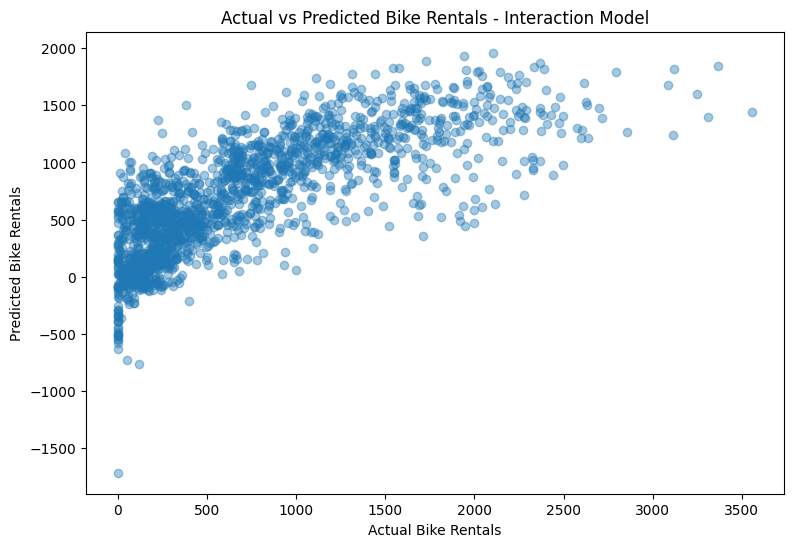

In [52]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred_interaction, alpha=0.4)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals - Interaction Model")

plt.show()

# Save the results

In [53]:
interaction_coefficients.to_csv(
    'Regression_With_Interaction_Coefficients.csv',
    index=False
)

interaction_comparison.to_csv(
    'Regression_With_Interaction_Predictions.csv',
    index=False
)

# Model Comparison and Business Interpretation

# Calculate evaluation metrics for both model

In [54]:
# Predictions from Model 1 (Without Interaction)
y_pred_model1 = model.predict(X_test)

# Predictions from Model 2 (With Interaction)
y_pred_model2 = model_interaction.predict(X_test_interaction)


# Function to calculate model performance
def evaluate_model(y_actual, y_pred, number_of_features):

    r2 = r2_score(y_actual, y_pred)

    n = len(y_actual)
    p = number_of_features

    adjusted_r2 = 1 - (
        (1 - r2) * (n - 1) / (n - p - 1)
    )

    mae = mean_absolute_error(y_actual, y_pred)
    mse = mean_squared_error(y_actual, y_pred)
    rmse = np.sqrt(mse)

    return [
        round(r2, 4),
        round(adjusted_r2, 4),
        round(mae, 2),
        round(rmse, 2)
    ]


# Evaluate both models
model1_results = evaluate_model(
    y_test, y_pred_model1, X_test.shape[1]
)

model2_results = evaluate_model(
    y_test, y_pred_model2, X_test_interaction.shape[1]
)


# Create comparison table
model_comparison = pd.DataFrame({
    'Performance Metric': [
        'R-squared',
        'Adjusted R-squared',
        'MAE',
        'RMSE'
    ],
    'Without Interaction': model1_results,
    'With Interaction': model2_results
})

display(model_comparison)

,Performance Metric,Without Interaction,With Interaction
0,R-squared,0.5329,0.5851
1,Adjusted R-squared,0.5294,0.5808
2,MAE,330.9500,301.3600
3,RMSE,441.1500,415.7500


# Identify the better model

In [55]:
if model2_results[0] > model1_results[0] and model2_results[2] < model1_results[2] and model2_results[3] < model1_results[3]:
    print("The Interaction Model performs better based on R-squared, MAE and RMSE.")

elif model1_results[0] > model2_results[0] and model1_results[2] < model2_results[2] and model1_results[3] < model2_results[3]:
    print("The Model Without Interaction performs better based on R-squared, MAE and RMSE.")

else:
    print("The results are mixed. Compare all performance metrics before selecting the final model.")

The Interaction Model performs better based on R-squared, MAE and RMSE.


# Visual comparison of R-squared

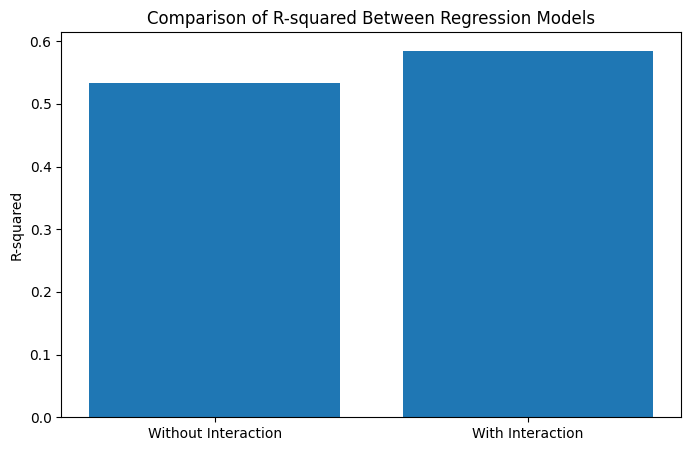

In [56]:
plt.figure(figsize=(8, 5))

models = ['Without Interaction', 'With Interaction']
r2_values = [model1_results[0], model2_results[0]]

plt.bar(models, r2_values)

plt.ylabel('R-squared')
plt.title('Comparison of R-squared Between Regression Models')

plt.show()

# Save the comparison table

In [58]:
model_comparison.to_csv(
    'Regression_Model_Comparison.csv',
    index=False
)

print("Model comparison file saved successfully.")

Model comparison file saved successfully.
